In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr

CITY = "Kolkata"

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "regions"
OUTPUT_DIR = PROJECT_DIR / f"series2_outputs/{CITY.lower()}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(DATA_DIR / f"{CITY}_cell_year_2015_2025.csv")

data["year"] = pd.to_numeric(data["year"], errors="coerce")

VARIABLES = ["lst_c", "ndbi", "ndvi"]
YEARS = list(range(2015, 2026))
MAP_YEARS = [2015, 2020, 2025]

sns.set_theme(style="whitegrid")

print(f"City: {CITY}")
print(f"Records: {len(data):,}")
print(f"Unique grid cells: {data['grid_id'].nunique():,}")
print(f"Years present: {sorted(data['year'].dropna().unique().astype(int))}")
print(f"Output directory: {OUTPUT_DIR}")
display(data.head())


City: Kolkata
Records: 42,174
Unique grid cells: 3,834
Years present: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Output directory: d:\sparkle\urban heat lockin\series2_outputs\kolkata


,grid_id,city_id,city,year,lst_c,ndvi,ndbi,n_obs_mean,l8_scenes,l9_scenes,sensor_mix
0,Kolkata_28375_9344,Kolkata,Kolkata,2015,33.821290,0.504450,-0.163883,6.000000,14,0,Landsat 8
1,Kolkata_28375_9344,Kolkata,Kolkata,2016,39.639694,0.540813,-0.196352,7.762062,14,0,Landsat 8
2,Kolkata_28375_9344,Kolkata,Kolkata,2017,34.633729,0.546385,-0.205817,8.000000,14,0,Landsat 8
3,Kolkata_28375_9344,Kolkata,Kolkata,2018,36.325811,0.583204,-0.234956,8.000000,12,0,Landsat 8
4,Kolkata_28375_9344,Kolkata,Kolkata,2019,37.229971,0.576347,-0.226970,10.000000,15,0,Landsat 8


,records,unique_cells,mean_observations
year,,,
2015,3834,3834,5.371166
2016,3834,3834,6.549256
2017,3834,3834,7.664124
2018,3834,3834,7.768766
2019,3834,3834,10.029517
2020,3834,3834,6.353777
2021,3834,3834,7.190904
2022,3834,3834,11.710074
2023,3834,3834,15.436994


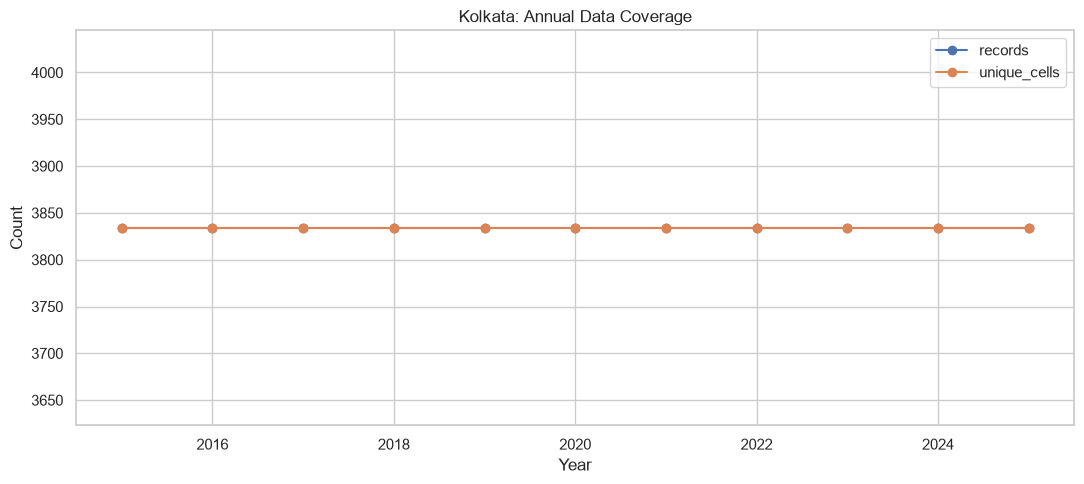

,missing_count,missing_percent
lst_c,0,0.0
ndbi,0,0.0
ndvi,0,0.0
n_obs_mean,0,0.0


In [2]:

# Number of records and unique grid cells per year
year_coverage = (
    data.groupby("year")
    .agg(
        records=("grid_id", "size"),
        unique_cells=("grid_id", "nunique"),
        mean_observations=("n_obs_mean", "mean")
    )
    .reindex(YEARS)
)

display(year_coverage)

ax = year_coverage[["records", "unique_cells"]].plot(
    figsize=(11, 5), marker="o"
)
ax.set_title(f"{CITY}: Annual Data Coverage")
ax.set_xlabel("Year")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_annual_coverage.png", dpi=200)
plt.show()

# Missing values
missing = data[VARIABLES + ["n_obs_mean"]].isna().sum().to_frame("missing_count")
missing["missing_percent"] = missing["missing_count"] / len(data) * 100
display(missing)

missing.to_csv(OUTPUT_DIR / "missing_values.csv")


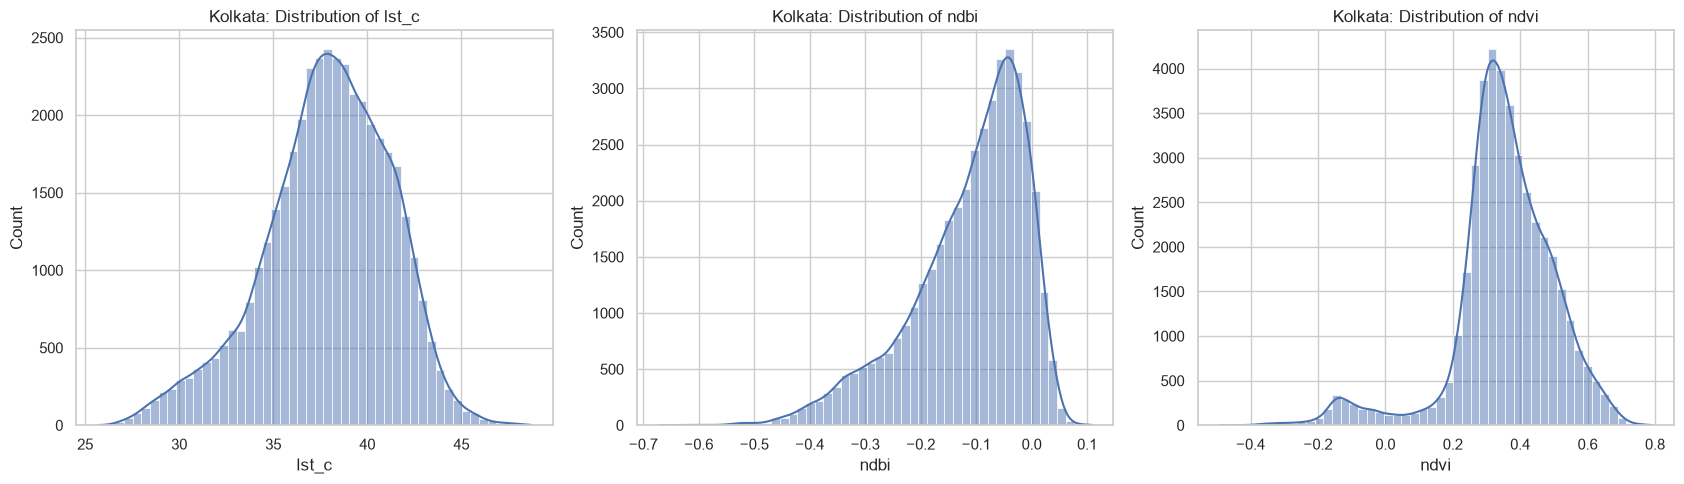

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
lst_c,42174.0,37.875969,3.384976,25.685044,28.879945,31.525899,35.860158,38.094152,40.308802,42.862661,44.603788,48.700165
ndbi,42174.0,-0.112881,0.103981,-0.672271,-0.414423,-0.325040,-0.168883,-0.088724,-0.035253,0.013497,0.038531,0.108247
ndvi,42174.0,0.352889,0.153248,-0.492465,-0.161812,0.053251,0.288209,0.354245,0.444605,0.578377,0.656033,0.792078


In [3]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, variable in zip(axes, VARIABLES):
    sns.histplot(
        data=data,
        x=variable,
        bins=50,
        kde=True,
        ax=ax
    )
    ax.set_title(f"{CITY}: Distribution of {variable}")
    ax.set_xlabel(variable)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_variable_distributions.png", dpi=200)
plt.show()

display(data[VARIABLES].describe(percentiles=[
    0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99
]).T)


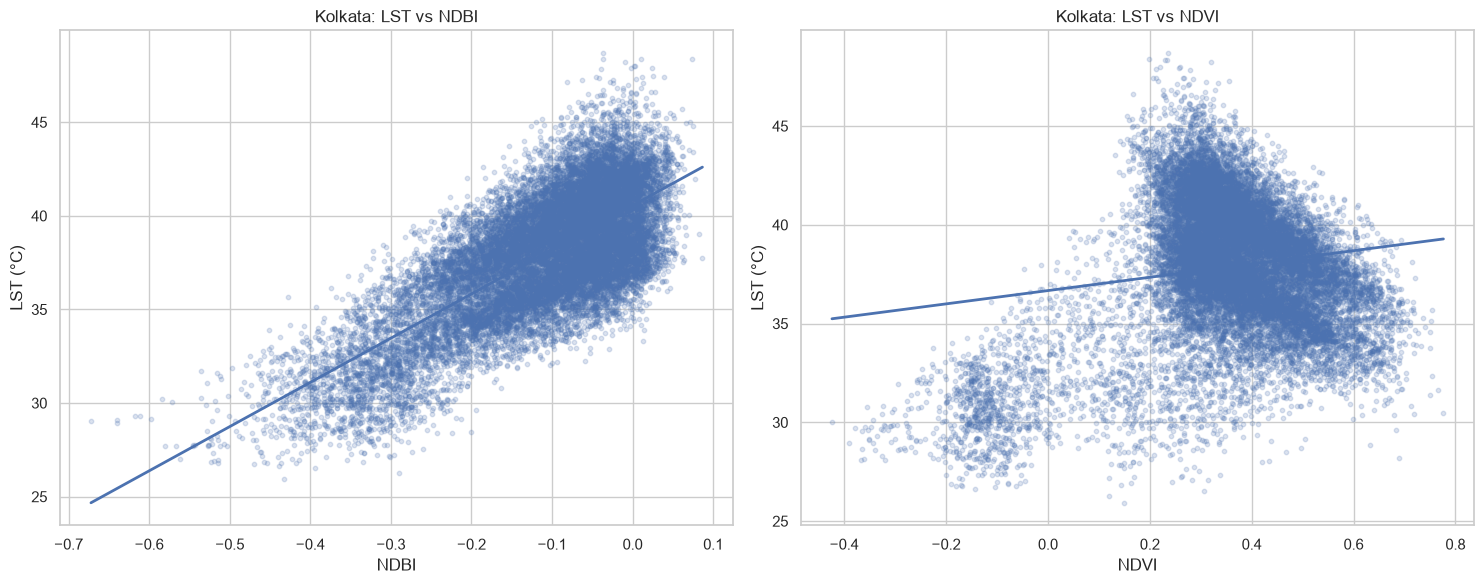

In [4]:

plot_data = data.dropna(subset=["lst_c", "ndbi", "ndvi"]).copy()

plot_sample = plot_data.sample(
    n=min(20000, len(plot_data)),
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, xvar, title in [
    (axes[0], "ndbi", "LST vs NDBI"),
    (axes[1], "ndvi", "LST vs NDVI")
]:
    sns.regplot(
        data=plot_sample,
        x=xvar,
        y="lst_c",
        ax=ax,
        scatter_kws={"alpha": 0.2, "s": 10},
        line_kws={"linewidth": 2},
        ci=None
    )
    ax.set_title(f"{CITY}: {title}")
    ax.set_xlabel(xvar.upper())
    ax.set_ylabel("LST (°C)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_lst_relationships.png", dpi=200)
plt.show()


In [5]:

PAIRS = [
    ("lst_c", "ndbi"),
    ("lst_c", "ndvi"),
    ("ndbi", "ndvi")
]

def calculate_correlations(df):
    results = []

    for x, y in PAIRS:
        pair = df[[x, y]].replace([np.inf, -np.inf], np.nan).dropna()
        n = len(pair)

        result = {
            "variable_1": x,
            "variable_2": y,
            "n": n,
            "pearson_r": np.nan,
            "pearson_p": np.nan,
            "spearman_rho": np.nan,
            "spearman_p": np.nan
        }

        if n >= 3 and pair[x].nunique() > 1 and pair[y].nunique() > 1:
            r, p = pearsonr(pair[x], pair[y])
            rho, sp = spearmanr(pair[x], pair[y])

            result.update({
                "pearson_r": r,
                "pearson_p": p,
                "spearman_rho": rho,
                "spearman_p": sp
            })

        results.append(result)

    return pd.DataFrame(results)

pooled_corr = calculate_correlations(data)
display(pooled_corr)
pooled_corr.to_csv(OUTPUT_DIR / "pooled_correlations.csv", index=False)

annual_corr = pd.concat(
    [
        calculate_correlations(group).assign(year=int(year))
        for year, group in data.groupby("year")
    ],
    ignore_index=True
)

display(annual_corr)
annual_corr.to_csv(OUTPUT_DIR / "annual_correlations.csv", index=False)


,variable_1,variable_2,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,lst_c,ndbi,42174,0.722948,0.000000e+00,0.636546,0.000000e+00
1,lst_c,ndvi,42174,0.150522,3.486979e-212,-0.139281,1.123444e-181
2,ndbi,ndvi,42174,-0.029572,1.245776e-09,-0.464237,0.000000e+00


,variable_1,variable_2,n,pearson_r,pearson_p,spearman_rho,spearman_p,year
0,lst_c,ndbi,3834,0.840518,0.000000e+00,0.762921,0.000000e+00,2015
1,lst_c,ndvi,3834,0.146303,8.620935e-20,-0.264331,2.601790e-62,2015
2,ndbi,ndvi,3834,0.108432,1.677274e-11,-0.461414,1.723490e-201,2015
3,lst_c,ndbi,3834,0.866457,0.000000e+00,0.798753,0.000000e+00,2016
4,lst_c,ndvi,3834,0.232763,2.463812e-48,-0.183878,1.664357e-30,2016
5,ndbi,ndvi,3834,0.021834,1.764765e-01,-0.429084,1.447302e-171,2016
6,lst_c,ndbi,3834,0.904767,0.000000e+00,0.878455,0.000000e+00,2017
7,lst_c,ndvi,3834,0.058259,3.071126e-04,-0.344217,4.287300e-107,2017
8,ndbi,ndvi,3834,-0.048161,2.855744e-03,-0.454204,1.558448e-194,2017
9,lst_c,ndbi,3834,0.843788,0.000000e+00,0.813009,0.000000e+00,2018


lst_c                                 ndbi                      \
           mean     median       std count      mean    median       std   
year                                                                       
2015  34.817874  35.040020  2.533688  3834 -0.120297 -0.088534  0.114451   
2016  40.815415  41.370150  3.070816  3834 -0.118656 -0.096263  0.096417   
2017  36.544533  37.075174  2.908462  3834 -0.117644 -0.095333  0.095447   
2018  38.773280  39.186584  3.092133  3834 -0.131311 -0.111123  0.094855   
2019  39.011301  39.430469  2.943547  3834 -0.131835 -0.106415  0.108392   
2020  37.820559  38.370950  3.037999  3834 -0.124549 -0.100088  0.109136   
2021  37.647293  37.946468  2.976212  3834 -0.087852 -0.058415  0.098570   
2022  36.453160  37.040467  2.779155  3834 -0.096786 -0.072504  0.096111   
2023  39.739705  40.486953  2.970831  3834 -0.103036 -0.078226  0.101380   
2024  39.163842  39.801913  3.095543  3834 -0.099903 -0.071633  0.106035   
2025  35.848697  36.329731  2.474972  3834 -0.109818 -0.082284  0.110531   

                ndvi                            
     count      mean    median       std count  
year                                            
2015  3834  0.343222  0.343370  0.147463  3834  
2016  3834  0.342211  0.342430  0.147155  3834  
2017  3834  0.346060  0.344916  0.143971  3834  
2018  3834  0.370226  0.368038  0.149841  3834  
2019  3834  0.367679  0.372476  0.162362  3834  
2020  3834  0.371388  0.383464  0.185321  3834  
2021  3834  0.323754  0.323240  0.140465  3834  
2022  3834  0.333018  0.330402  0.147914  3834  
2023  3834  0.360150  0.361223  0.146705  3834  
2024  3834  0.355050  0.353792  0.151019  3834  
2025  3834  0.369022  0.370112  0.149981  3834

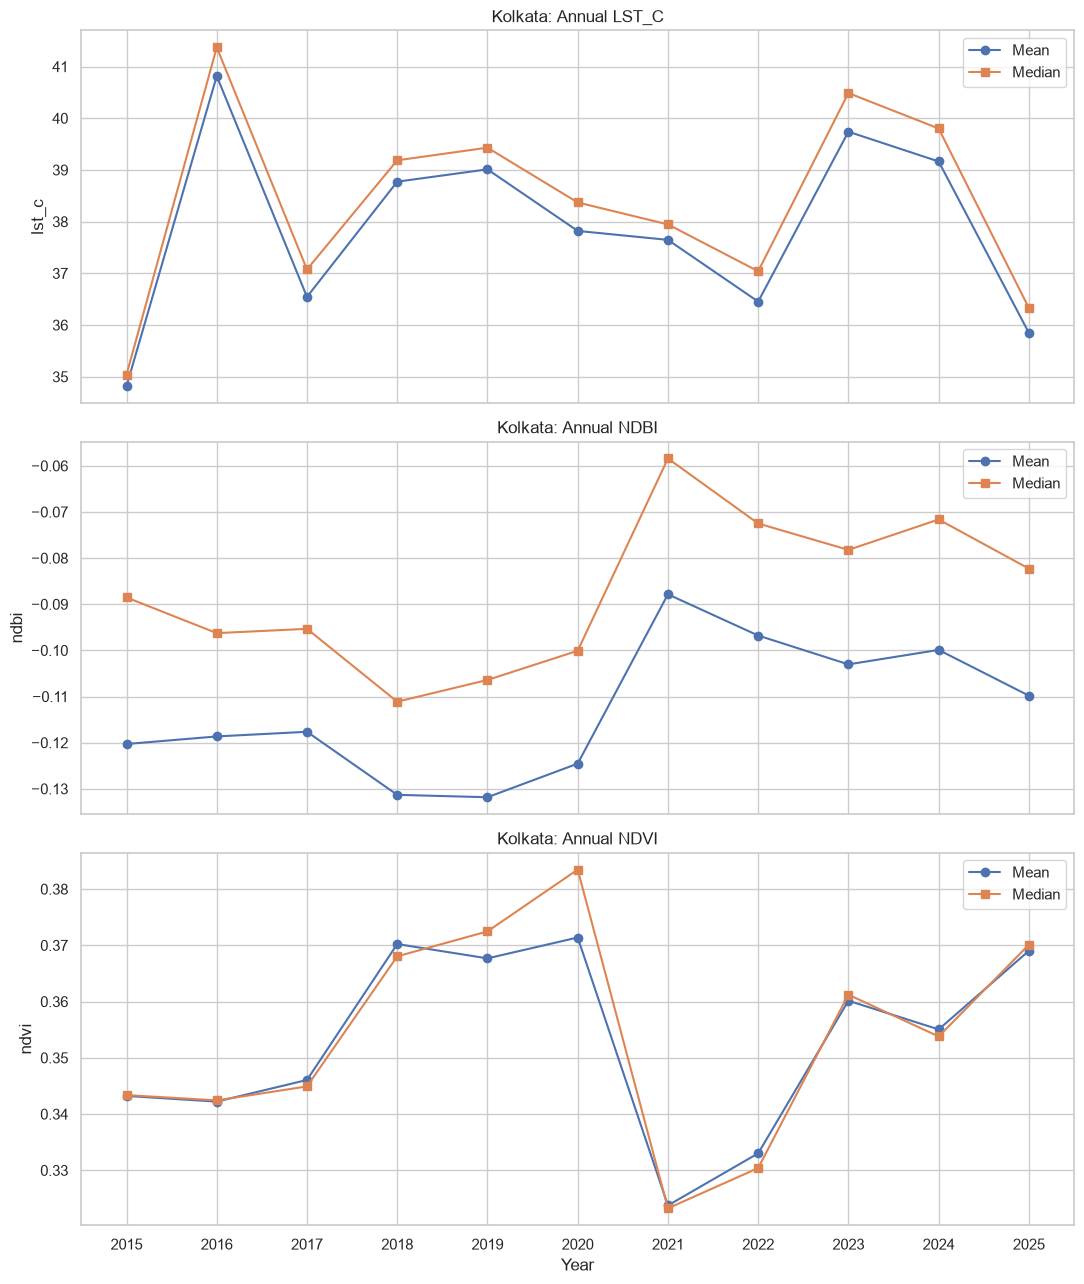

In [6]:

annual_stats = (
    data.groupby("year")[VARIABLES]
    .agg(["mean", "median", "std", "count"])
    .reindex(YEARS)
)

display(annual_stats)
annual_stats.to_csv(OUTPUT_DIR / "annual_summary_statistics.csv")

fig, axes = plt.subplots(3, 1, figsize=(11, 13), sharex=True)

for ax, variable in zip(axes, VARIABLES):
    stats = data.groupby("year")[variable].agg(["mean", "median"])

    ax.plot(stats.index, stats["mean"], marker="o", label="Mean")
    ax.plot(stats.index, stats["median"], marker="s", label="Median")

    ax.set_title(f"{CITY}: Annual {variable.upper()}")
    ax.set_ylabel(variable)
    ax.legend()

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(YEARS)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_annual_trends.png", dpi=200)
plt.show()


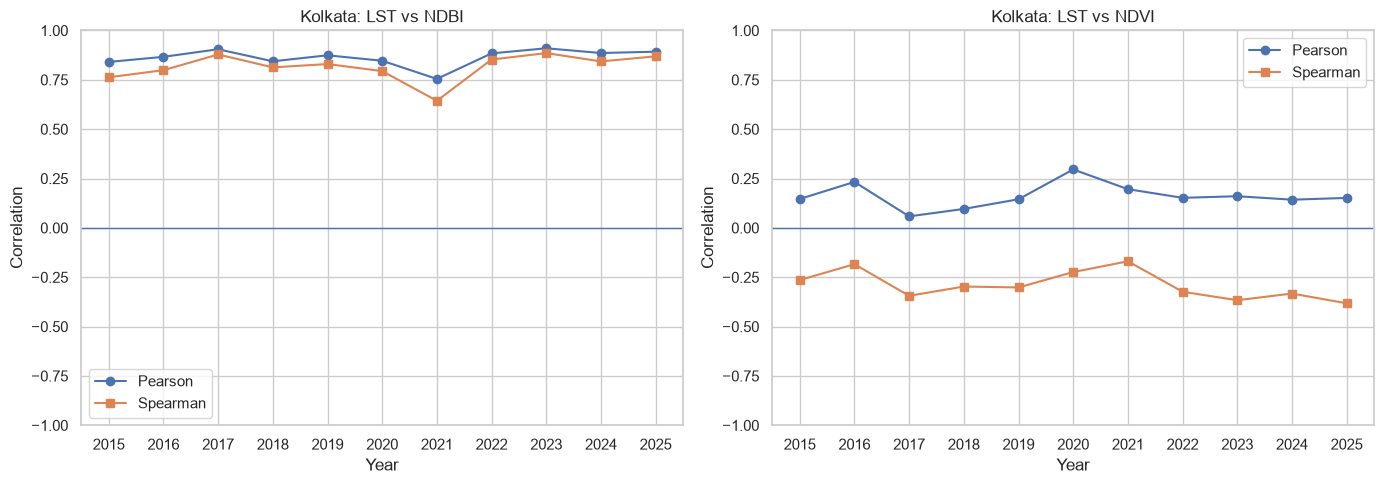

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, xvar, title in [
    (axes[0], "ndbi", "LST vs NDBI"),
    (axes[1], "ndvi", "LST vs NDVI")
]:
    subset = annual_corr[
        (annual_corr["variable_1"] == "lst_c") &
        (annual_corr["variable_2"] == xvar)
    ]

    ax.plot(
        subset["year"], subset["pearson_r"],
        marker="o", label="Pearson"
    )
    ax.plot(
        subset["year"], subset["spearman_rho"],
        marker="s", label="Spearman"
    )
    ax.axhline(0, linewidth=1)
    ax.set_title(f"{CITY}: {title}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Correlation")
    ax.set_ylim(-1, 1)
    ax.set_xticks(YEARS)
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_annual_correlations.png", dpi=200)
plt.show()


Grid columns: ['grid_id', 'in_frac', 'city_id', 'geometry']
Grid CRS: PROJCS["WGS 84 / World Cylindrical Equal Area",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433]],PROJECTION["Cylindrical_Equal_Area"],PARAMETER["central_meridian",0],PARAMETER["standard_parallel_1",30],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["m",1],AXIS["X",EAST],AXIS["Y",NORTH]]
Number of grid cells: 3834


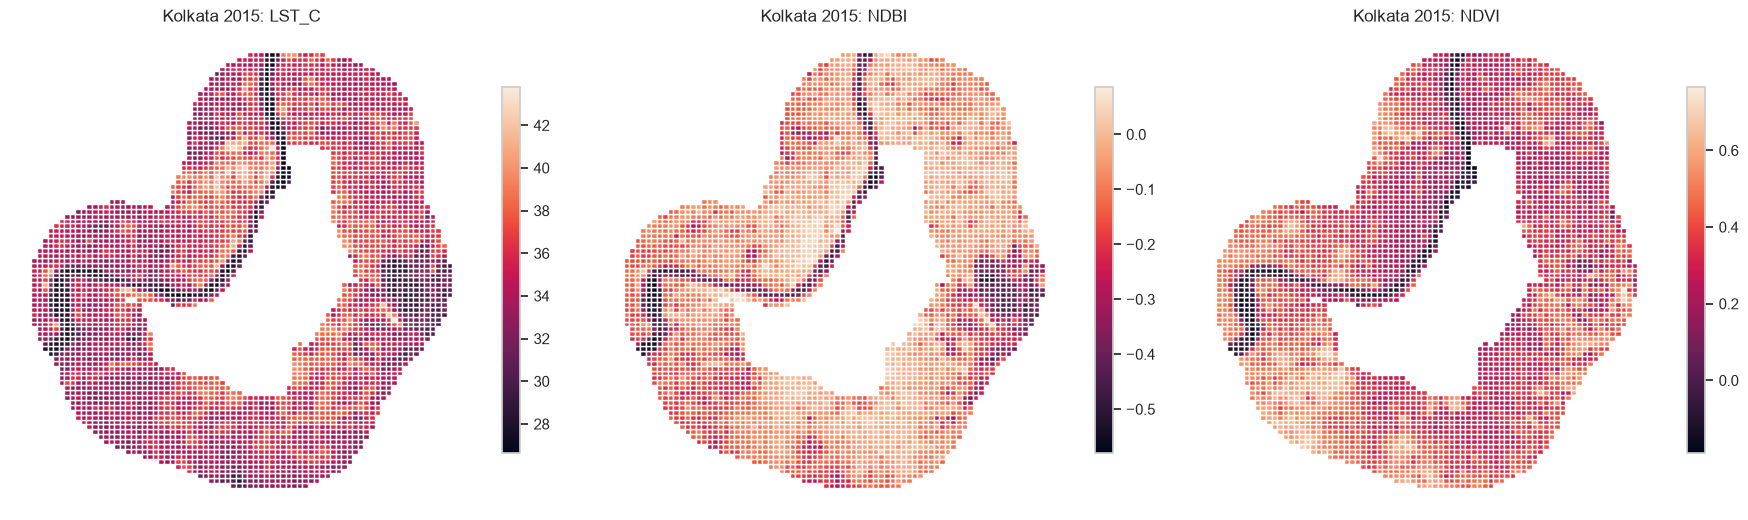

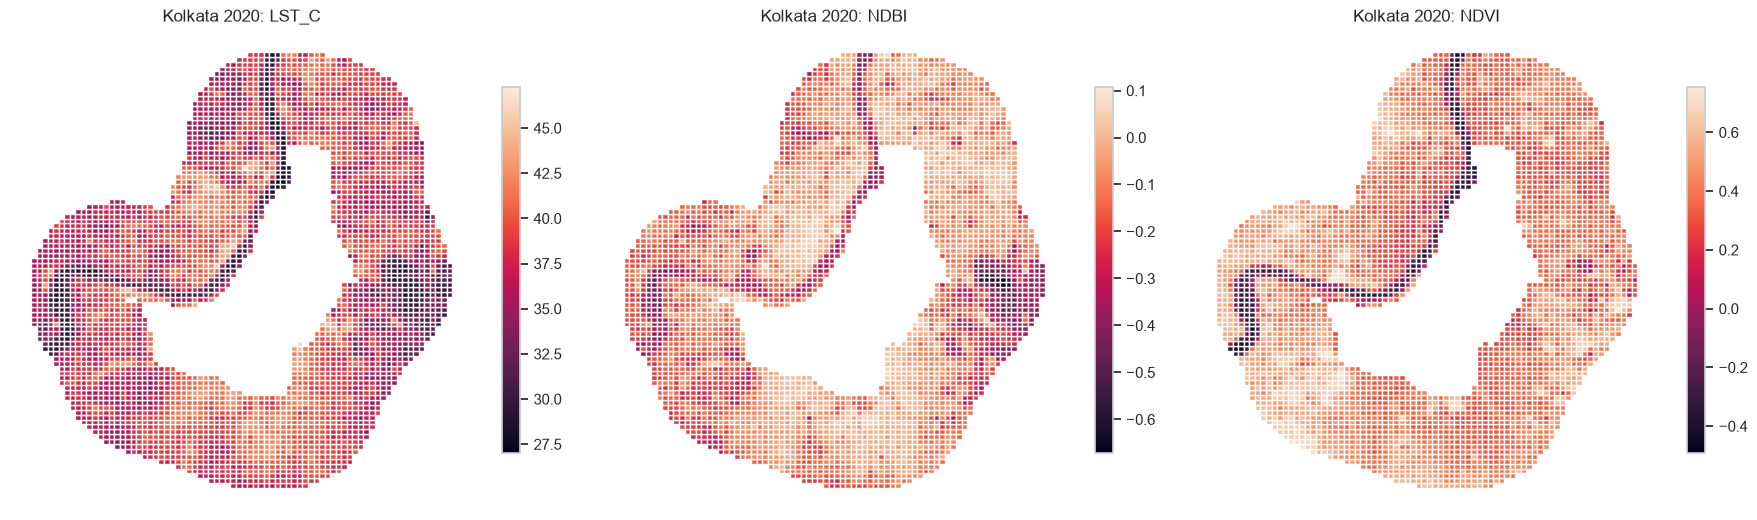

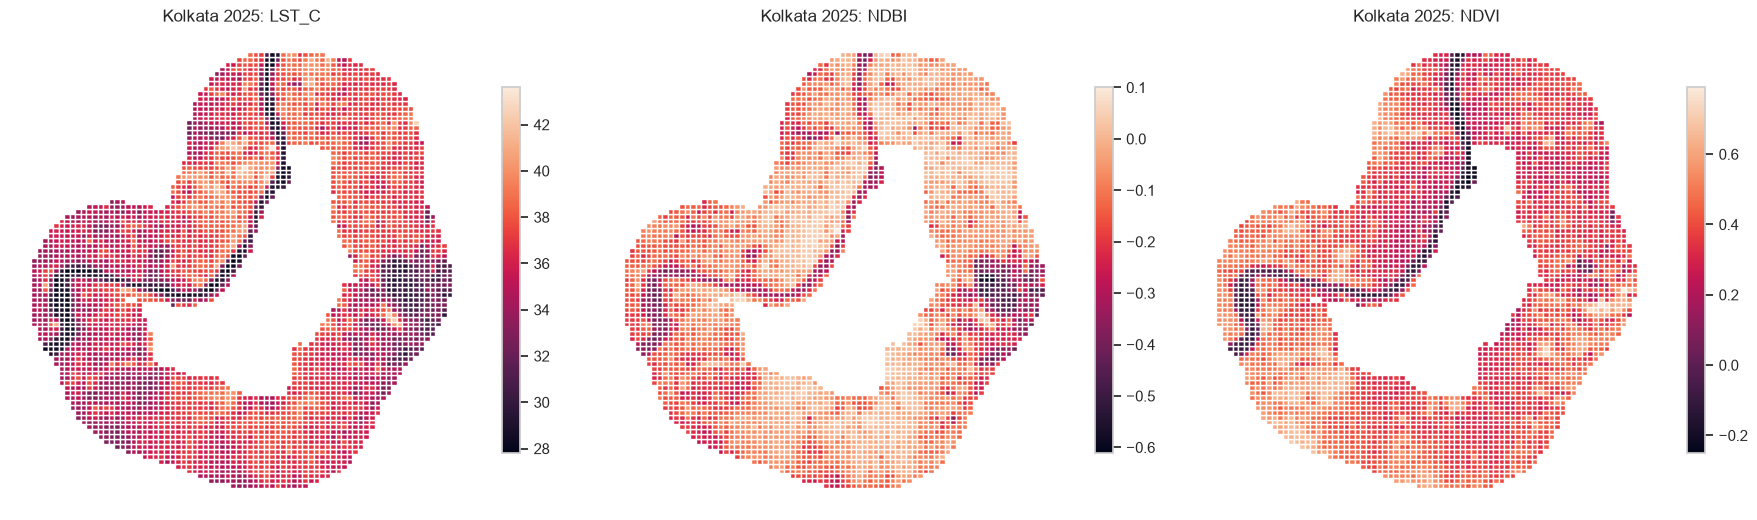

In [8]:

import geopandas as gpd
from pathlib import Path

# Change this path to your actual 300 m grid shapefile
SHAPEFILE_PATH = PROJECT_DIR / "grids" / f"{CITY}_Grid_300m.shp"

if not SHAPEFILE_PATH.exists():
    print(f"Shapefile not found: {SHAPEFILE_PATH}")
else:
    grid = gpd.read_file(SHAPEFILE_PATH)

    print("Grid columns:", grid.columns.tolist())
    print("Grid CRS:", grid.crs)
    print("Number of grid cells:", len(grid))

    if "grid_id" not in grid.columns:
        raise ValueError(
            "The shapefile has no grid_id column. "
            "Check its column names and identify the matching grid ID field."
        )

    grid["grid_id"] = grid["grid_id"].astype(str)
    data["grid_id"] = data["grid_id"].astype(str)

    if grid.crs is None:
        raise ValueError("The shapefile has no CRS defined.")

    grid = grid.to_crs("EPSG:4326")

    for year in MAP_YEARS:
        year_data = data.loc[
            data["year"] == year,
            ["grid_id"] + VARIABLES
        ]

        joined = grid.merge(
            year_data,
            on="grid_id",
            how="left",
            validate="one_to_one"
        )

        fig, axes = plt.subplots(1, 3, figsize=(18, 6))

        for ax, variable in zip(axes, VARIABLES):
            joined.plot(
                column=variable,
                ax=ax,
                legend=True,
                missing_kwds={
                    "color": "lightgrey",
                    "label": "No data"
                },
                legend_kwds={"shrink": 0.65}
            )
            ax.set_title(f"{CITY} {year}: {variable.upper()}")
            ax.set_axis_off()

        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / f"map_{CITY}_{year}.png",
            dpi=200,
            bbox_inches="tight"
        )
        plt.show()
